In [1]:
package CarKeeperRequirements {
    doc /* Требования к веб-приложению CarKeeper (планировщик ТО автомобиля).
        Версия 0.2 (после рецензирования). */

    private import ScalarValues::*;

    // ---------- Участники и система ----------
    part def Owner;          // пользователь — владелец автомобиля
    part def Administrator;
    part def MailServer;     // внешний SMTP-сервер

    part def CarKeeper {
        part accountModule;
        part garageModule;
        part planModule;
        part dueDateCalculator;   // ядро: расчёт сроков и статусов
        part journalModule;
        part notificationModule;
        part reportModule;
    }

    // ---------- Базовые определения требований ----------
    requirement def FunctionalRequirement {
        attribute priority : String;   // MoSCoW: Must | Should | Could
        attribute iteration : Integer;
        subject system : CarKeeper;
    }
    requirement def QualityRequirement {
        attribute metric : String;
        subject system : CarKeeper;
    }

    // ---------- Функциональные требования ----------
    requirement carKeeperSpec {
        doc /* Корневое требование: вести историю обслуживания автомобиля,
            планировать замену расходников и напоминать о предстоящем ТО. */

        requirement accessAndRoles {
            requirement <'REQ-FUNC-001'> func001 : FunctionalRequirement {
                doc /* Регистрация и вход. */
                attribute :>> priority = "Must"; attribute :>> iteration = 1;
            }
            requirement <'REQ-FUNC-002'> func002 : FunctionalRequirement {
                doc /* Роли и права доступа. */
                attribute :>> priority = "Must"; attribute :>> iteration = 1;
            }
        }

        requirement garageGroup {
            requirement <'REQ-FUNC-003'> func003 : FunctionalRequirement {
                doc /* Управление автомобилями. */
                attribute :>> priority = "Must"; attribute :>> iteration = 1;
            }
            requirement <'REQ-FUNC-004'> func004 : FunctionalRequirement {
                doc /* Ввод показаний пробега; v = (M2 - M1) / (D2 - D1). */
                attribute :>> priority = "Must"; attribute :>> iteration = 1;
            }
            requirement <'REQ-FUNC-019'> func019 : FunctionalRequirement {
                doc /* Сезонная смена шин (добавлено в v0.2). */
                attribute :>> priority = "Should"; attribute :>> iteration = 2;
            }
            requirement <'REQ-FUNC-020'> func020 : FunctionalRequirement {
                doc /* Сроки документов: страховка, техосмотр (добавлено в v0.2). */
                attribute :>> priority = "Should"; attribute :>> iteration = 2;
            }
        }

        requirement planGroup {
            requirement <'REQ-FUNC-005'> func005 : FunctionalRequirement {
                doc /* Справочник регламентов ТО. */
                attribute :>> priority = "Must"; attribute :>> iteration = 1;
            }
            requirement <'REQ-FUNC-006'> func006 : FunctionalRequirement {
                doc /* План ТО автомобиля. */
                attribute :>> priority = "Must"; attribute :>> iteration = 1;
            }
            requirement <'REQ-FUNC-007'> func007 : FunctionalRequirement {
                doc /* Срок = min(D_last + T, D_cur + (M_last + L - M_cur) / v). */
                attribute :>> priority = "Must"; attribute :>> iteration = 1;
            }
            requirement <'REQ-FUNC-008'> func008 : FunctionalRequirement {
                doc /* Статусы: В норме / Скоро (1000 км или 30 дней) / Просрочено. */
                attribute :>> priority = "Must"; attribute :>> iteration = 1;
            }
        }

        requirement journalGroup {
            requirement <'REQ-FUNC-009'> func009 : FunctionalRequirement {
                doc /* Запись в журнал (v0.2: производитель и артикул расходника). */
                attribute :>> priority = "Must"; attribute :>> iteration = 1;
            }
            requirement <'REQ-FUNC-010'> func010 : FunctionalRequirement {
                doc /* Закрытие позиций плана записью журнала. */
                attribute :>> priority = "Must"; attribute :>> iteration = 1;
            }
            requirement <'REQ-FUNC-013'> func013 : FunctionalRequirement {
                doc /* Вложения к записи: JPEG, PNG, PDF до 10 МБ. */
                attribute :>> priority = "Could"; attribute :>> iteration = 3;
            }
        }

        requirement reminderGroup {
            requirement <'REQ-FUNC-011'> func011 : FunctionalRequirement {
                doc /* Напоминания по e-mail. */
                attribute :>> priority = "Should"; attribute :>> iteration = 2;
            }
            requirement <'REQ-FUNC-012'> func012 : FunctionalRequirement {
                doc /* Уведомления в приложении. */
                attribute :>> priority = "Should"; attribute :>> iteration = 2;
            }
            requirement <'REQ-FUNC-016'> func016 : FunctionalRequirement {
                doc /* Календарь предстоящих работ на 12 месяцев. */
                attribute :>> priority = "Should"; attribute :>> iteration = 2;
            }
        }

        requirement reportGroup {
            requirement <'REQ-FUNC-014'> func014 : FunctionalRequirement {
                doc /* Отчёт о расходах за период. */
                attribute :>> priority = "Should"; attribute :>> iteration = 2;
            }
            requirement <'REQ-FUNC-015'> func015 : FunctionalRequirement {
                doc /* Экспорт истории в PDF. */
                attribute :>> priority = "Could"; attribute :>> iteration = 3;
            }
            requirement <'REQ-FUNC-017'> func017 : FunctionalRequirement {
                doc /* Импорт и экспорт журнала в CSV. */
                attribute :>> priority = "Could"; attribute :>> iteration = 3;
            }
            requirement <'REQ-FUNC-018'> func018 : FunctionalRequirement {
                doc /* Прогноз расходов на 12 месяцев. */
                attribute :>> priority = "Could"; attribute :>> iteration = 3;
            }
        }
    }

    // ---------- Нефункциональные требования ----------
    requirement qualitySpec {
        requirement <'REQ-PERF-001'> perf001 : QualityRequirement {
            attribute :>> metric = "Ответ страницы <= 1,5 с для 95 % запросов";
        }
        requirement <'REQ-PERF-002'> perf002 : QualityRequirement {
            attribute :>> metric = "Пересчёт плана <= 1 с";
        }
        requirement <'REQ-PERF-003'> perf003 : QualityRequirement {
            attribute :>> metric = "PDF на 200 записей <= 5 с";
        }
        requirement <'REQ-PERF-004'> perf004 : QualityRequirement {
            attribute :>> metric = "Проверка 10 000 автомобилей <= 10 мин";
        }
        requirement <'REQ-SEC-001'> sec001 : QualityRequirement {
            attribute :>> metric = "bcrypt, стоимость >= 10";
        }
        requirement <'REQ-SEC-003'> sec003 : QualityRequirement {
            attribute :>> metric = "Чужие объекты -> 404";
        }
        requirement <'REQ-SEC-004'> sec004 : QualityRequirement {
            attribute :>> metric = "Сеанс 30 мин; 5 попыток -> блокировка 15 мин";
        }
        requirement <'REQ-REL-001'> rel001 : QualityRequirement {
            attribute :>> metric = "Напоминание не дублируется";
        }
        requirement <'REQ-REL-002'> rel002 : QualityRequirement {
            attribute :>> metric = "3 повтора SMTP: 1, 5, 25 мин";
        }
        requirement <'REQ-AVAIL-001'> avail001 : QualityRequirement {
            attribute :>> metric = "Доступность >= 99 % в месяц";
        }
        requirement <'REQ-MAINT-001'> maint001 : QualityRequirement {
            attribute :>> metric = "Покрытие модуля расчёта >= 90 %";
        }
        requirement <'REQ-COST-001'> cost001 : QualityRequirement {
            attribute :>> metric = "Хостинг <= 10 USD/мес";
        }
        // полный перечень — раздел 3.3–3.5 файла srs.md
    }

    // ---------- Варианты использования ----------
    use case def AddCar        { subject system : CarKeeper; actor owner : Owner; }
    use case def EnterMileage  { subject system : CarKeeper; actor owner : Owner; }
    use case def ViewPlan      { subject system : CarKeeper; actor owner : Owner; }
    use case def AddRecord     { subject system : CarKeeper; actor owner : Owner; }
    use case def CloseItems    { subject system : CarKeeper; actor owner : Owner; }
    use case def ViewExpenses  { subject system : CarKeeper; actor owner : Owner; }
    use case def ExportPdf     { subject system : CarKeeper; actor owner : Owner; }
    use case def ManageTyres   { subject system : CarKeeper; actor owner : Owner; }
    use case def TrackDocuments{ subject system : CarKeeper; actor owner : Owner; }
    use case def ManageRegulations { subject system : CarKeeper; actor admin : Administrator; }
    use case def SendReminders {
        subject system : CarKeeper;
        actor owner : Owner;
        actor mail : MailServer;
    }

    // Сводный вариант использования для диаграммы (рисунок 3.1)
    use case carKeeperUseCases {
        subject system : CarKeeper;
        actor owner : Owner;
        actor admin : Administrator;
        actor mail : MailServer;
        include use case addCar : AddCar;
        include use case viewPlan : ViewPlan {
            include use case enterMileage : EnterMileage;
        }
        include use case addRecord : AddRecord {
            include use case closeItems : CloseItems;
        }
        include use case viewExpenses : ViewExpenses {
            include use case exportPdf : ExportPdf;
        }
        include use case manageTyres : ManageTyres;
        include use case trackDocuments : TrackDocuments;
        include use case sendReminders : SendReminders;
        include use case manageRegulations : ManageRegulations;
    }

    use case addRecord : AddRecord {
        include use case closeItems : CloseItems;
    }
    use case viewPlan : ViewPlan {
        include use case enterMileage : EnterMileage;
    }

    // ---------- Удовлетворение требований ----------
    part carKeeper : CarKeeper;
    satisfy carKeeperSpec.planGroup.func007 by carKeeper.dueDateCalculator;
    satisfy carKeeperSpec.planGroup.func008 by carKeeper.dueDateCalculator;
    satisfy carKeeperSpec.reminderGroup.func011 by carKeeper.notificationModule;
    satisfy carKeeperSpec.reportGroup.func014 by carKeeper.reportModule;
    satisfy carKeeperSpec.journalGroup.func009 by carKeeper.journalModule;
}


Package CarKeeperRequirements (74797648-b814-4f40-9985-95043fd3085b)


In [2]:
package CarKeeperDomain {
    // Модель предметной области CarKeeper (приложение В спецификации).
    // Композиция («владеет») записана как part, ссылки — как ref.
    // Версия 0.2: добавлены TyreSet, CarDocument, RecordPart.

    private import ScalarValues::*;

    enum def Role { owner; admin; }
    enum def EngineType { petrol; diesel; hybrid; electric; }
    enum def Status { ok; soon; overdue; }
    enum def Season { summer; winter; allSeason; }

    part def User {
        attribute email : String;
        attribute passwordHash : String;
        attribute role : Role;
        attribute remindByEmail : Boolean;
        attribute warnKm : Integer;
        attribute warnDays : Integer;
        part cars : Car[0..*];
    }

    part def Car {
        attribute make : String;
        attribute model : String;
        attribute year : Integer;
        attribute engineType : EngineType;
        attribute vin : String;
        attribute annualMileage : Integer;
        attribute archived : Boolean;
        part readings : MileageReading[0..*];
        part plan : PlanItem[1..*];
        part records : ServiceRecord[0..*];
        part tyres : TyreSet[0..*];
        part documents : CarDocument[0..*];
    }

    part def MileageReading {
        attribute date : String;
        attribute mileage : Integer;
    }

    part def Regulation {
        attribute name : String;
        attribute engineType : EngineType;
        part items : RegulationItem[1..*];
    }

    part def RegulationItem {
        attribute title : String;
        attribute category : String;
        attribute intervalKm : Integer;
        attribute intervalMonths : Integer;
    }

    part def PlanItem {
        attribute title : String;
        attribute intervalKm : Integer;
        attribute intervalMonths : Integer;
        attribute lastDate : String;
        attribute lastMileage : Integer;
        attribute enabled : Boolean;
        ref source : RegulationItem[0..1];
        part notifications : Notification[0..*];
    }

    part def ServiceRecord {
        attribute date : String;
        attribute mileage : Integer;
        attribute place : String;
        attribute labourCost : Real;
        attribute total : Real;
        part parts : RecordPart[0..*];
        part attachments : Attachment[0..5];
        ref closes : PlanItem[0..*];
    }

    part def RecordPart {
        attribute name : String;
        attribute manufacturer : String;
        attribute partNumber : String;
        attribute quantity : Integer;
        attribute price : Real;
    }

    part def Attachment {
        attribute fileName : String;
        attribute contentType : String;
        attribute size : Integer;
    }

    part def Notification {
        attribute status : Status;
        attribute createdAt : String;
        attribute read : Boolean;
    }

    part def TyreSet {
        attribute season : Season;
        attribute brand : String;
        attribute mileage : Integer;
        attribute installed : Boolean;
    }

    part def CarDocument {
        attribute type : String;
        attribute expiresAt : String;
    }
}


Package CarKeeperDomain (3402ab0f-380f-42c5-b5d4-ed3fefe99f90)


In [3]:
package CarKeeperUI {
    doc /* Прототип пользовательского интерфейса CarKeeper в нотации SysML v2.
        Каждый экран — part def, наследующий Screen; его части — элементы
        интерфейса (поля, таблицы, кнопки), порядок частей задаёт компоновку.
        Мокапы srs/img/mock-*.png генерируются из этого файла скриптом
        srs/sysml/ui-render/render_ui.py. Версия 0.2. */

    private import ScalarValues::*;
    private import CarKeeperRequirements::*;

    // ---------- Библиотека элементов интерфейса ----------
    part def Widget {
        attribute label : String;
        attribute width : Integer;      // относительная ширина в строке
    }
    part def Screen :> Widget {
        attribute title : String;
        attribute subtitle : String;
        attribute activeMenu : String;  // выделенный пункт бокового меню
        attribute userInfo : String;
    }
    part def SideMenu :> Widget { attribute items : String; }
    part def Row :> Widget;             // дочерние элементы располагаются по горизонтали
    part def Card :> Widget;            // группа элементов с заголовком label
    part def Field :> Widget { attribute value : String; attribute required : Boolean; }
    part def Button :> Widget { attribute primary : Boolean; }
    part def Table :> Widget {
        attribute columns : String;     // через «|»
        attribute rows : String;        // строки через «;», ячейки через «|», [статус] — значок
    }
    part def CheckList :> Widget { attribute items : String; attribute checked : String; }
    part def Kpi :> Widget { attribute value : String; }
    part def BarChart :> Widget { attribute values : String; attribute captions : String; }
    part def Tabs :> Widget { attribute items : String; attribute active : String; }
    part def Note :> Widget;

    part mainMenu : SideMenu {
        attribute :>> items = "Панель|Мои автомобили|План ТО|Журнал|Расходы|Календарь|Администрирование";
    }

    // ---------- Экран «Панель» (REQ-FUNC-004, 008, 012) ----------
    part def DashboardScreen :> Screen {
        attribute :>> title = "Панель";
        attribute :>> subtitle = "Сегодня 01.11.2026 · 2 автомобиля";
        attribute :>> activeMenu = "Панель";
        attribute :>> userInfo = "owner@example.com · Пользователь";
        part addRecord : Button { attribute :>> label = "+ Запись в журнал"; attribute :>> primary = true; }
        part top : Row {
            part mileageCard : Card {
                attribute :>> label = "Ввод пробега"; attribute :>> width = 5;
                part car : Field { attribute :>> label = "Автомобиль"; attribute :>> value = "Skoda Octavia 1.6 MPI · 7777 AB-7"; }
                part line : Row {
                    part mileage : Field { attribute :>> label = "Текущий пробег, км *"; attribute :>> value = "56 000"; attribute :>> width = 3; }
                    part save : Button { attribute :>> label = "Сохранить пробег"; attribute :>> primary = true; attribute :>> width = 2; }
                }
                part hint : Note { attribute :>> label = "Предыдущее показание: 55 120 км (18.10.2026) · средний пробег 39 км/сут"; }
            }
            part counters : Card {
                attribute :>> label = "Статусы"; attribute :>> width = 2;
                part overdue : Kpi { attribute :>> label = "просрочено"; attribute :>> value = "2"; }
                part soon : Kpi { attribute :>> label = "скоро"; attribute :>> value = "3"; }
            }
            part notifications : Card {
                attribute :>> label = "Уведомления (3)"; attribute :>> width = 4;
                part list : CheckList {
                    attribute :>> items = "Салонный фильтр просрочен (Octavia)|Тормозная жидкость — до 15.11.2026|Страховка Polo истекает 30.11.2026|Пора менять шины на зимние";
                    attribute :>> checked = "4";
                }
            }
        }
        part upcoming : Card {
            attribute :>> label = "Предстоящие работы";
            part works : Table {
                attribute :>> columns = "Автомобиль|Работа|Срок|Осталось|Статус";
                attribute :>> rows = "Octavia|Замена салонного фильтра|20.10.2026|−12 дн.|[Просрочено];Polo|Замена ремня ГРМ|07.10.2026|−1 000 км|[Просрочено];Octavia|Замена тормозной жидкости|15.11.2026|14 дн.|[Скоро];Polo|Замена моторного масла|21.11.2026|800 км|[Скоро];Polo|Страховка (документ)|30.11.2026|29 дн.|[Скоро];Octavia|Замена моторного масла|09.02.2027|4 000 км|[В норме]";
            }
        }
    }

    // ---------- Экран «План ТО» (REQ-FUNC-006, 007, 008, 019) ----------
    part def PlanScreen :> Screen {
        attribute :>> title = "План ТО — Skoda Octavia 1.6 MPI";
        attribute :>> subtitle = "Регламент: бензин · пробег 56 000 км на 01.11.2026 · пороги 1000 км / 30 дней";
        attribute :>> activeMenu = "План ТО";
        attribute :>> userInfo = "owner@example.com · Пользователь";
        part thresholds : Button { attribute :>> label = "Пороги"; }
        part addItem : Button { attribute :>> label = "+ Добавить работу"; attribute :>> primary = true; }
        part items : Card {
            attribute :>> label = "Позиции плана";
            part plan : Table {
                attribute :>> columns = "Работа|Интервал|Последнее выполнение|Следующий срок|Статус";
                attribute :>> rows = "Замена салонного фильтра|15 000 км / 12 мес|20.10.2025 · 45 000 км|20.10.2026 (по времени)|[Просрочено];Замена тормозной жидкости|40 000 км / 24 мес|15.11.2024 · 30 000 км|15.11.2026 (по времени)|[Скоро];Замена моторного масла|10 000 км / 12 мес|10.03.2026 · 50 000 км|09.02.2027 (≈ 60 000 км)|[В норме];Замена масляного фильтра|10 000 км / 12 мес|10.03.2026 · 50 000 км|09.02.2027 (≈ 60 000 км)|[В норме];Проверка тормозных колодок|30 000 км / —|01.05.2026 · 50 000 км|23.06.2028 (≈ 80 000 км)|[В норме];Замена воздушного фильтра|30 000 км / 24 мес|10.03.2026 · 50 000 км|10.03.2028|[В норме];Замена ремня ГРМ|90 000 км / 60 мес|01.06.2023 · 20 000 км|01.06.2028|[В норме];Шины: зимние (Nokian, 12 400 км)|с 15.10 / с 01.04|18.10.2026 · 55 120 км|01.04.2027 — на летние|[В норме]";
            }
        }
        part disclaimer : Note { attribute :>> label = "Интервалы носят рекомендательный характер. Сверяйтесь с руководством по эксплуатации."; }
    }

    // ---------- Экран «Новая запись журнала» (REQ-FUNC-009, 010, 013) ----------
    part def RecordScreen :> Screen {
        attribute :>> title = "Новая запись журнала";
        attribute :>> subtitle = "Skoda Octavia 1.6 MPI";
        attribute :>> activeMenu = "Журнал";
        attribute :>> userInfo = "owner@example.com · Пользователь";
        part cancel : Button { attribute :>> label = "Отмена"; }
        part save : Button { attribute :>> label = "Сохранить"; attribute :>> primary = true; }
        part main : Card {
            attribute :>> label = "Основные данные";
            part line : Row {
                part date : Field { attribute :>> label = "Дата *"; attribute :>> value = "01.11.2026"; }
                part mileage : Field { attribute :>> label = "Пробег, км *"; attribute :>> value = "56 000"; }
                part place : Field { attribute :>> label = "Где выполнено"; attribute :>> value = "СТО «АвтоМастер»"; attribute :>> width = 2; }
            }
        }
        part middle : Row {
            part closes : Card {
                attribute :>> label = "Выполненные позиции плана"; attribute :>> width = 2;
                part items : CheckList {
                    attribute :>> items = "Замена салонного фильтра|Замена тормозной жидкости|Замена моторного масла|Замена масляного фильтра";
                    attribute :>> checked = "1|2";
                }
            }
            part partsCard : Card {
                attribute :>> label = "Расходники"; attribute :>> width = 5;
                part parts : Table {
                    attribute :>> columns = "Наименование|Производитель|Артикул|Кол-во|Цена, BYN";
                    attribute :>> rows = "Фильтр салонный угольный|Mann-Filter|CUK 2939|1|38,00;Тормозная жидкость DOT 4, 1 л|ATE|03.9901-6402.2|1|32,50;+ добавить расходник||||";
                }
                part totals : Row {
                    part labour : Field { attribute :>> label = "Стоимость работ, BYN"; attribute :>> value = "60,00"; }
                    part total : Field { attribute :>> label = "Итого, BYN"; attribute :>> value = "130,50"; }
                }
            }
        }
        part extra : Row {
            part commentField : Field { attribute :>> label = "Комментарий"; attribute :>> value = "Проверить передние колодки при следующем ТО"; attribute :>> width = 3; }
            part attach : Field { attribute :>> label = "Вложения (JPEG, PNG, PDF ≤ 10 МБ)"; attribute :>> value = "chek_011126.jpg  + прикрепить"; attribute :>> width = 2; }
        }
    }

    // ---------- Экран «Расходы» (REQ-FUNC-014, 015, 018) ----------
    part def ExpensesScreen :> Screen {
        attribute :>> title = "Расходы";
        attribute :>> subtitle = "Skoda Octavia 1.6 MPI · 01.11.2025 – 31.10.2026";
        attribute :>> activeMenu = "Расходы";
        attribute :>> userInfo = "owner@example.com · Пользователь";
        part csv : Button { attribute :>> label = "Экспорт CSV"; }
        part pdf : Button { attribute :>> label = "Экспорт истории в PDF"; attribute :>> primary = true; }
        part kpis : Row {
            part total : Kpi { attribute :>> label = "Всего за период"; attribute :>> value = "1 284,50 BYN"; }
            part distance : Kpi { attribute :>> label = "Пробег за период"; attribute :>> value = "14 200 км"; }
            part perKm : Kpi { attribute :>> label = "Стоимость 1 км"; attribute :>> value = "0,09 BYN"; }
            part forecast : Kpi { attribute :>> label = "Прогноз на 12 мес."; attribute :>> value = "≈ 740 BYN"; }
        }
        part charts : Row {
            part byMonth : Card {
                attribute :>> label = "По месяцам, BYN"; attribute :>> width = 3;
                part chart : BarChart {
                    attribute :>> values = "64|21|0|32|412|86|11|107|0|21|171|54";
                    attribute :>> captions = "11|12|01|02|03|04|05|06|07|08|09|10";
                }
            }
            part byCategory : Card {
                attribute :>> label = "По категориям"; attribute :>> width = 2;
                part categories : Table {
                    attribute :>> columns = "Категория|Сумма, BYN|Доля";
                    attribute :>> rows = "Жидкости|395,00|31 %;Тормоза|248,00|19 %;Двигатель|215,00|17 %;Фильтры|186,50|15 %;Шины|120,00|9 %;Прочее|120,00|9 %;Итого|1 284,50|100 %";
                }
            }
        }
    }

    // ---------- Экран «Регламенты ТО» (REQ-FUNC-005) ----------
    part def AdminRegulationsScreen :> Screen {
        attribute :>> title = "Регламенты ТО";
        attribute :>> subtitle = "Изменения не затрагивают уже созданные планы автомобилей";
        attribute :>> activeMenu = "Администрирование";
        attribute :>> userInfo = "admin@example.com · Администратор";
        part add : Button { attribute :>> label = "+ Добавить работу"; attribute :>> primary = true; }
        part engine : Tabs { attribute :>> items = "Бензин|Дизель|Гибрид|Электро"; attribute :>> active = "Бензин"; }
        part list : Card {
            attribute :>> label = "Работы регламента";
            part items : Table {
                attribute :>> columns = "Работа|Категория|Интервал, км|Интервал, мес.|В планах";
                attribute :>> rows = "Замена моторного масла|Жидкости|10 000|12|1 284;Замена масляного фильтра|Фильтры|10 000|12|1 284;Замена воздушного фильтра|Фильтры|30 000|24|1 280;Замена салонного фильтра|Фильтры|15 000|12|1 271;Замена свечей зажигания|Двигатель|30 000|36|1 262;Замена тормозной жидкости|Тормоза|40 000|24|1 284;Проверка/замена колодок|Тормоза|30 000|—|1 284;Замена охлаждающей жидкости|Жидкости|60 000|48|1 250;Замена масла в КПП|Жидкости|60 000|48|977;Замена ремня ГРМ|Двигатель|90 000|60|812";
            }
        }
        part rule : Note { attribute :>> label = "Должен быть задан хотя бы один интервал (REQ-FUNC-005)."; }
    }

    // ---------- Навигация между экранами ----------
    part def CarKeeperWebUI {
        part dashboard : DashboardScreen;
        part plan : PlanScreen;
        part record : RecordScreen;
        part expenses : ExpensesScreen;
        part admin : AdminRegulationsScreen;

        first dashboard then plan;      // клик по работе на панели
        first plan then record;         // кнопка «Выполнено»
        first record then plan;         // после сохранения записи
        first dashboard then expenses;
        first dashboard then admin;     // только для администратора
    }

    // ---------- Связь экранов с требованиями ----------
    part ui : CarKeeperWebUI;
    satisfy carKeeperSpec.garageGroup.func004 by ui.dashboard;
    satisfy carKeeperSpec.planGroup.func008 by ui.dashboard;
    satisfy carKeeperSpec.reminderGroup.func012 by ui.dashboard;
    satisfy carKeeperSpec.planGroup.func006 by ui.plan;
    satisfy carKeeperSpec.planGroup.func007 by ui.plan;
    satisfy carKeeperSpec.garageGroup.func019 by ui.plan;
    satisfy carKeeperSpec.journalGroup.func009 by ui.record;
    satisfy carKeeperSpec.journalGroup.func010 by ui.record;
    satisfy carKeeperSpec.journalGroup.func013 by ui.record;
    satisfy carKeeperSpec.reportGroup.func014 by ui.expenses;
    satisfy carKeeperSpec.reportGroup.func015 by ui.expenses;
    satisfy carKeeperSpec.reportGroup.func018 by ui.expenses;
    satisfy carKeeperSpec.planGroup.func005 by ui.admin;
}


Package CarKeeperUI (5b053a55-c488-4873-a393-10c5615430a7)


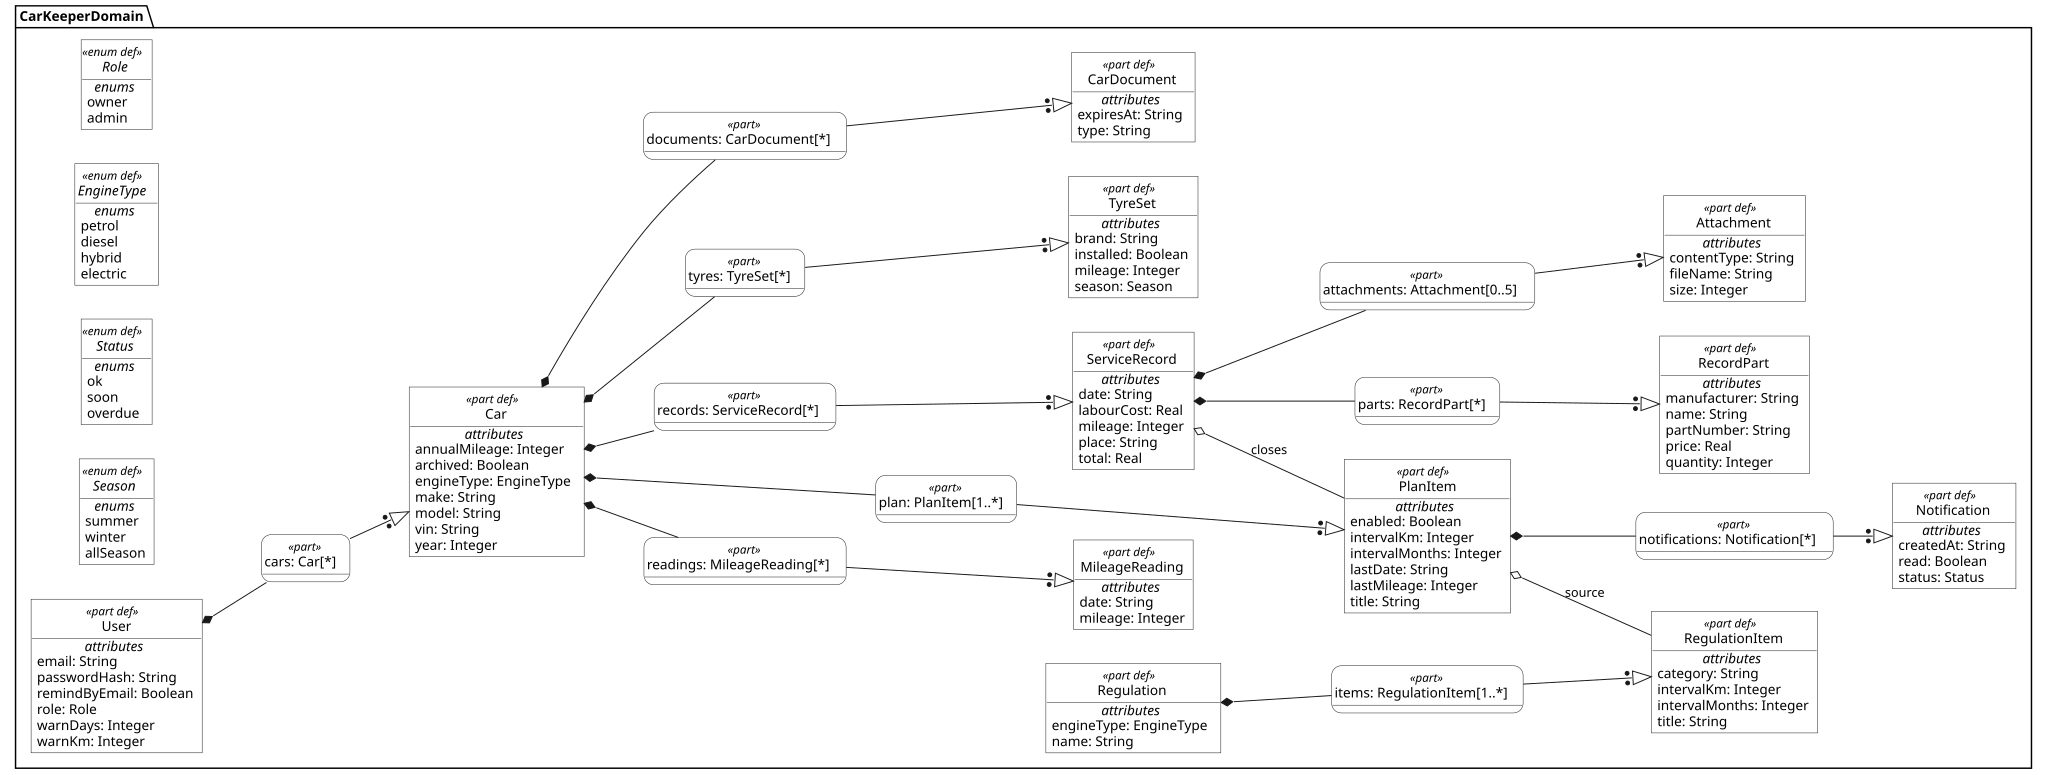

In [4]:
%viz --view=tree --style=LR CarKeeperDomain

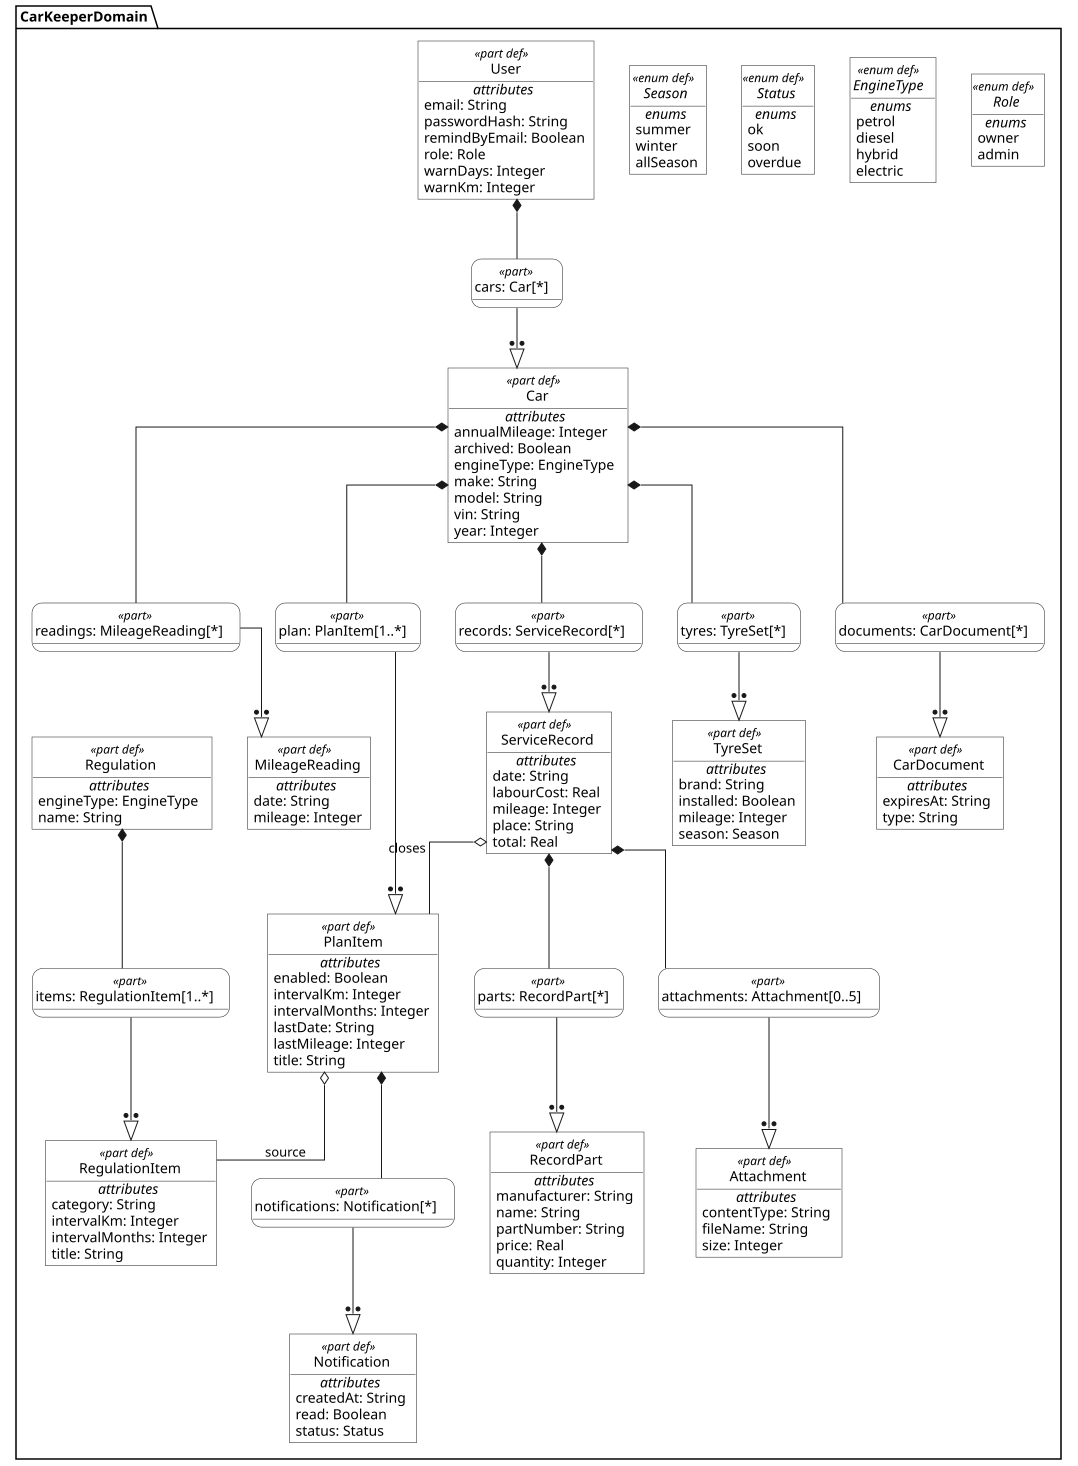

In [5]:
%viz --view=tree --style=ORTHOLINE CarKeeperDomain